# 10 &nbsp;What if we could not randomize? Difference-in-differences

**A different kind of question.** Everything so far came from a randomized test. Many of the decisions that matter most can't be randomized: a price change in one market, a policy in one state, a feature launched to everyone at once. The question is the same (*what difference did it make?*) but the comparison group has to be built after the fact.

**The case.** In November 1988 California passed **Proposition 99**: a 25 cent tax on every pack of cigarettes, with the money going to anti-smoking programs. Did it reduce smoking, and by how much? The data is cigarette packs sold per person in California and 38 other states from 1970 to 2000 (Abadie, Diamond and Hainmueller, 2010). The states that passed similar programs during the period are already left out.

**The method here is difference-in-differences (DiD):** compare California's change after 1988 with the other states' change over the same years. It rests on one assumption, **parallel trends**: without the policy, California would have moved in step with the others. This notebook tests that assumption before trusting the answer.

In [1]:
import numpy as np
import pandas as pd

from exptoolkit import plots, style
from exptoolkit.causal import did, event_study, load_smoking, placebo_band

style.use_style()
panel = load_smoking()
treated, start = "California", 1989
others = panel.drop(columns=treated).mean(axis=1)
print(f"{panel.shape[1]} states, {panel.index.min()} to {panel.index.max()}")

39 states, 1970 to 2000


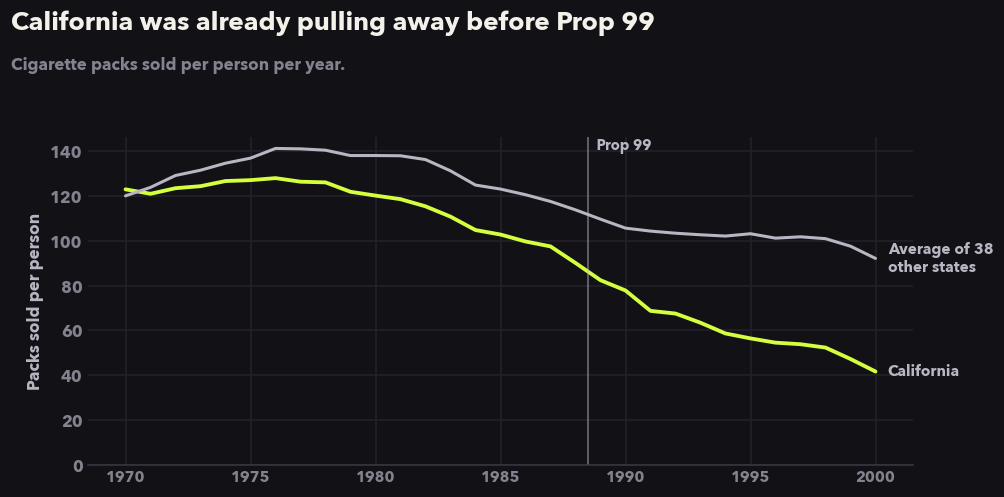

In [2]:
fig, ax = plots.trend_plot({"California": (panel[treated], "treated"),
                           "Average of 38\nother states": (others, "average")}, start, "Packs sold per person")
style.headline(fig, "California was already pulling away before Prop 99", "Cigarette packs sold per person per year.")
style.save(fig, "tobacco_trends")

## 1. The difference-in-differences estimate

In [3]:
pre, post = panel.index < start, panel.index >= start
table = pd.DataFrame({
    "1970 to 1988": [panel.loc[pre, treated].mean(), others[pre].mean()],
    "1989 to 2000": [panel.loc[post, treated].mean(), others[post].mean()],
}, index=["California", "Other states"])
table["Change"] = table["1989 to 2000"] - table["1970 to 1988"]
estimate = did(panel, treated, start)
print(f"Difference-in-differences: {estimate:.1f} packs per person per year")
table.round(1)

Difference-in-differences: -27.3 packs per person per year


,1970 to 1988,1989 to 2000,Change
California,116.2,60.4,-55.9
Other states,130.6,102.1,-28.5


Taken at face value, Prop 99 cut sales by about **27 packs per person per year**. But that number is only as good as the parallel trends assumption.

## 2. Check the assumption: an event study

Plot the gap between California and the other states for every year, measured relative to 1988. If the two were moving in parallel before the policy, the gap would hover around zero for every year before 1989. To judge what "around zero" means for a single state, the grey band shows the same gap for every other state, each taking a turn as the fake "treated" state.

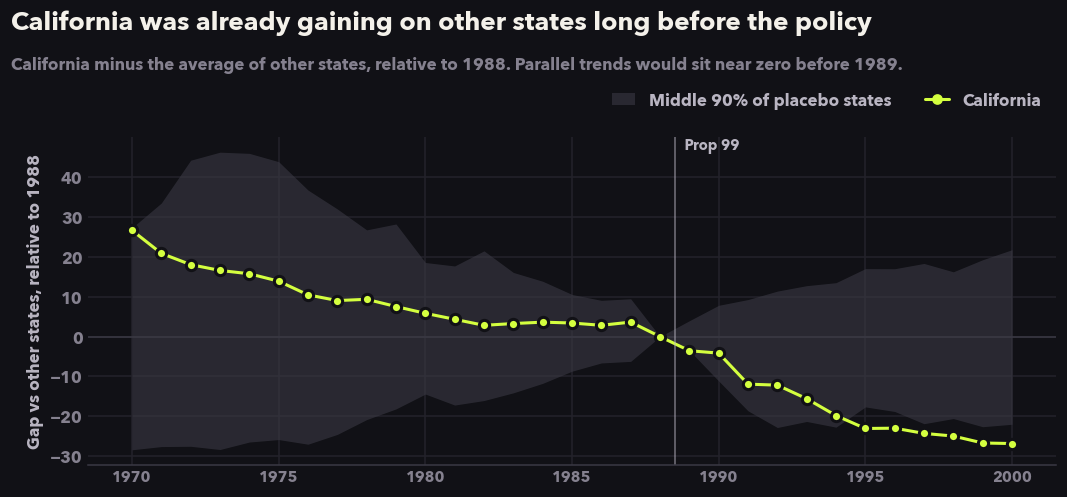

In [4]:
es = event_study(panel, treated, reference=1988)
band = placebo_band(panel, treated, lambda donors, unit: event_study(donors, unit, reference=1988))
fig, ax = plots.event_study_plot(es, band, start)
style.headline(fig, "California was already gaining on other states long before the policy",
               "California minus the average of other states, relative to 1988. Parallel trends would sit near zero before 1989.")
style.save(fig, "event_study")

Before 1989 the gap is not flat. In 1970 California sold about as many packs per person as the average state (3 more). By 1980 it sold 18 fewer, and by 1988 about 24 fewer. California was cutting back on cigarettes faster than the average state *before* any tax. Some of what DiD credits to Prop 99 is a trend that was already under way.

The grey band is also wide: for many states, "the average of everyone else" is a poor comparison. That is a warning about the method, not just about California.

## 3. A placebo in time

A sharper check: pretend the policy happened in **1980**, and run the same DiD using only years before the real policy. Nothing happened in 1980, so a sound method should find roughly zero.

In [5]:
fake = did(panel.loc[:1988], treated, 1980)
print(f"Fake 1980 'effect', using only pre-policy years: {fake:.1f} packs per person per year")

Fake 1980 'effect', using only pre-policy years: -11.5 packs per person per year


DiD finds an "effect" of about **12 packs** from a policy that never existed. That is the pre-existing trend showing up as if it were an impact, and it is a large share of the 27 packs found for the real policy.

## What this tells us

- **DiD gives a number fast: about 27 fewer packs per person per year.**
- **But its key assumption fails here.** California was already diverging from the average state, and a fake 1980 policy shows an effect of around 12 packs. The real effect is very likely smaller than 27.
- **The fix is a better comparison, not a fancier formula.** Instead of the average of all other states, build a blend of states that actually moved like California before 1989. That is a synthetic control, and it is notebook 11.

*The general habit:* never report a difference-in-differences estimate without the event study next to it. If the lines weren't parallel before, the estimate after isn't trustworthy.